# HuGaDB: сравнение четырёх методов

Эксперимент использует небольшую подвыборку **целых записей**. Границы файлов и переходы между действиями сохраняются. Участники из train, conf и test не пересекаются.

Полный локальный HuGaDB содержит 12 классов. Два класса исключены из эксперимента:

1) bicycling
2) sitting_in_car

Оба класса записаны только для участника 01. Поэтому для них нельзя построить независимое разделение по участникам. В эксперименте остаются 10 классов, и каждый из них присутствует в train, conf и test.

Для запуска выберите **Run All** в окружении /home/sasha/Documents/venv. Расчёты выполняются в памяти и не создают дополнительных файлов. Это компактная проверка переноса методов на HuGaDB, а не полный benchmark набора данных.

In [53]:
from pathlib import Path
from itertools import product
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
if not (ROOT / "comparison_methods.py").exists():
    ROOT = ROOT / "Unitree_g1_causal_command_segmentation"
# Импортируем локальный модуль. Настройки передаются через аргументы функций.
sys.path.insert(0, str(ROOT.resolve()))
importlib.invalidate_caches()
import constants
constants = importlib.reload(constants)
import comparison_methods as cm
cm = importlib.reload(cm)  # Используем актуальную версию локального модуля.

DATA = ROOT / "dataset" / "HuGaDB"
SEED = 42
# Используем среднюю частоту из статьи. В локальных CSV нет временных меток.
SAMPLE_HZ = 56.35
WINDOW, STRIDE = round(SAMPLE_HZ), round(0.1 * SAMPLE_HZ)
DT = STRIDE / SAMPLE_HZ  # Шаг между окнами в секундах.
# Эти классы есть только у участника 01. Честная межсубъектная оценка для них невозможна.
EXCLUDED_CLASSES = {"bicycling", "sitting_in_car"}
SUBJECTS = {"train": ("04", "05", "08",), "conf": ("06",), "test": ("07", "09",)}
EXPECTED_CLASSES = {
    "walking", "running", "going_up", "going_down", "sitting", "sitting_down",
    "standing_up", "standing", "bicycling", "up_by_elevator",
    "down_by_elevator", "sitting_in_car",
}

### 1. Подвыборка и разделение
Для инвентаризации читаем только столбец меток каждого файла. Классы bicycling и sitting_in_car исключены, потому что оба есть только у участника 01.

Для остальных 10 классов выбираем целые записи без пересечения участников. Очередность выбора такая:

1) запись покрывает больше ещё не представленных классов
2) запись короче
3) имя файла идёт раньше по алфавиту

Сигналы загружаются только для выбранных записей.

In [54]:
files = sorted(DATA.glob("*.csv"))

inventory = []
for path in files:
    labels = pd.read_csv(path, usecols=["activity"])["activity"]

    inventory.append({
        "path": path, "subject": path.stem.split("_")[-2],
        "rows": len(labels), "classes": frozenset(labels.unique()),
    })
available = set().union(*(r["classes"] for r in inventory))

class_names = sorted(available - EXCLUDED_CLASSES)
class_to_id = {name: i + 1 for i, name in enumerate(class_names)}
CLASS_IDS = tuple(class_to_id.values())
class_files = pd.DataFrame({
    "class": class_names,
    "files_with_class": [sum(name in r["classes"] for r in inventory) for name in class_names],
})
print(f"Всего файлов: {len(files)}. Классов в полном наборе: {len(available)}. В эксперименте: {len(class_names)}.")
display(class_files)
print("Исключены из эксперимента (есть только у участника 01):", sorted(EXCLUDED_CLASSES))

classes_by_subject = {
    subject: set().union(*(r["classes"] for r in inventory if r["subject"] == subject)) & set(class_names)
    for subject in set().union(*map(set, SUBJECTS.values()))
}

def cover_subject(subject):
    pool = [r for r in inventory if r["subject"] == subject and r["rows"] >= WINDOW]
    missing, chosen = set(classes_by_subject[subject]), []
    while missing:
        candidates = [r for r in pool if r["classes"] & missing]

        best = min(candidates, key=lambda r: (
            -len(r["classes"] & missing), r["rows"], r["path"].name))
        chosen.append(best)
        pool.remove(best)
        missing -= best["classes"]
    return chosen

selected = {split: [r for subject in subjects for r in cover_subject(subject)]
            for split, subjects in SUBJECTS.items()}
subject_sets = [set(s) for s in SUBJECTS.values()]

split_classes = {split: set().union(*(r["classes"] for r in records)) & set(class_names)
                 for split, records in selected.items()}

print("Все 10 рабочих классов есть в каждом разделе. Участники между разделами не пересекаются.")

manifest = pd.DataFrame([
    {"split": split, "subject": r["subject"], "file": r["path"].name,
     "samples": r["rows"], "classes": ", ".join(sorted(r["classes"]))}
    for split, records in selected.items() for r in records
])
display(manifest)

print(f"Выбрано записей: {len(manifest)}/{len(files)}. "
      f"{manifest.samples.sum() / sum(r['rows'] for r in inventory):.1%} отсчётов.")


Всего файлов: 635. Классов в полном наборе: 12. В эксперименте: 10.


,class,files_with_class
0,down_by_elevator,40
1,going_down,87
2,going_up,85
3,running,78
4,sitting,157
5,sitting_down,75
6,standing,369
7,standing_up,80
8,up_by_elevator,41
9,walking,316


Исключены из эксперимента (есть только у участника 01): ['bicycling', 'sitting_in_car']
Все 10 рабочих классов есть в каждом разделе. Участники между разделами не пересекаются.


,split,subject,file,samples,classes
0,train,04,HuGaDB_v1_various_04_00.csv,1296,"sitting, sitting_down, standing, standing_up"
1,train,04,HuGaDB_v1_various_04_13.csv,7080,"down_by_elevator, standing, up_by_elevator, wa..."
2,train,04,HuGaDB_v1_various_04_18.csv,1266,"running, walking"
3,train,04,HuGaDB_v1_various_04_08.csv,2646,"going_down, standing, walking"
4,train,04,HuGaDB_v1_various_04_07.csv,3012,"going_up, standing, walking"
5,train,05,HuGaDB_v1_various_05_03.csv,1726,"sitting, sitting_down, standing, standing_up"
6,train,05,HuGaDB_v1_various_05_20.csv,1988,"running, standing, walking"
7,train,05,HuGaDB_v1_various_05_16.csv,3075,"down_by_elevator, standing, up_by_elevator"
8,train,05,HuGaDB_v1_various_05_06.csv,2270,"going_down, standing, walking"
9,train,05,HuGaDB_v1_various_05_11.csv,4777,"going_up, standing, walking"


Выбрано записей: 30/635. 3.5% отсчётов.


### 2. Признаки и переиспользование функций
Длительность окна около одной секунды. Решение относится к **концу окна**, а эталонной меткой служит последний отсчёт окна.

По 38 каналам вычисляются 152 признака:

1) среднее
2) стандартное отклонение
3) RMS
4) RMS первых разностей

StandardScaler и PCA до 16 компонент обучаются только на train.

In [55]:
def make_split(records):
    features, targets, metadata = [], [], []
    for r in records:
        df = pd.read_csv(r["path"])
        columns = [c for c in df if c.startswith(("accelerometer_", "gyroscope_", "EMG_"))]

        signal = df[columns].to_numpy(dtype=float)

        labels = df.activity.map(class_to_id).to_numpy(dtype=int)
        for start in range(0, len(df) - WINDOW + 1, STRIDE):
            stop = start + WINDOW
            w = signal[start:stop]
            features.append(np.r_[w.mean(0), w.std(0),
                                  np.sqrt(np.mean(w ** 2, axis=0)),
                                  np.sqrt(np.mean(np.diff(w, axis=0) ** 2, axis=0))])
            targets.append(labels[stop - 1])
            metadata.append((r["path"].stem, start, stop - 1))

    X, y = np.asarray(features), np.asarray(targets)
    meta = pd.DataFrame(metadata, columns=["record_id", "window_start_frame", "window_end_frame"])

    return X, y, meta

In [56]:
splits = {split: make_split(records) for split, records in selected.items()}
scaler = StandardScaler().fit(splits["train"][0])

pca = PCA(n_components=16, svd_solver="full", random_state=SEED).fit(
    scaler.transform(splits["train"][0]))

splits = {s: (pca.transform(scaler.transform(X)), y, meta)
          for s, (X, y, meta) in splits.items()}

In [57]:
display(pd.DataFrame({s: pd.Series(y).value_counts().reindex(CLASS_IDS, fill_value=0)
                      for s, (_, y, _) in splits.items()})
        .rename(index={v: k for k, v in class_to_id.items()}))
print("Доля объяснённой дисперсии PCA:", round(pca.explained_variance_ratio_.sum(), 3))

N_ACTIONS, N_SUBACTIONS = len(CLASS_IDS), 2 * len(CLASS_IDS)
LABEL_NAMES = {v: k for k, v in class_to_id.items()}
FSM_PARAMS = dict(neutral_id=class_to_id["standing"], label_names=LABEL_NAMES, distractor_id=None)
METRIC_PARAMS = dict(active_command_ids=CLASS_IDS, window_step_seconds=DT,
                     iou_threshold=cm.EVENT_IOU_THRESHOLD)

slices = {s: cm.record_slices(tuple(meta.record_id.drop_duplicates()), meta)[0]
          for s, (_, _, meta) in splits.items()}
print(f"Прототипы первого и второго уровней: {N_ACTIONS}/{N_SUBACTIONS}.")
print(f"Порог IoU: {cm.EVENT_IOU_THRESHOLD}. Шаг окна: {DT:.4f} с.")


,train,conf,test
down_by_elevator,727,122,492
going_down,368,39,322
going_up,680,49,440
running,397,382,189
sitting,361,91,187
sitting_down,134,44,114
standing,1422,440,872
standing_up,131,33,106
up_by_elevator,1078,285,261
walking,1522,262,377


Доля объяснённой дисперсии PCA: 0.94
Прототипы первого и второго уровней: 10/20.
Порог IoU: 0.5. Шаг окна: 0.1065 с.


### 3. Обучение на train и выбор параметров на conf

Переключатель **M4_SELECTION_MODE** находится в **constants.py**. Сейчас включён **f1**: максимум Event-F1@50, затем минимум ложных активаций, p95 и медианы задержки. Вариант **reliability** сохраняет альтернативное правило ниже.

Для M4 сначала сравниваем лучший Event-F1@50 с максимумом среди M1, выбранного M2 и M3 на conf. Если этот уровень достижим, оставляем варианты M4 не хуже него. Иначе оставляем варианты не ниже 95% лучшего F1 самого M4. Среди допустимых вариантов минимизируем ложные активации, затем двойные команды, p95 и медиану задержки. При полном равенстве выбираем больший F1. Относительный допуск задан в constants.py как M4_F1_TOLERANCE. Правило применяется отдельно для K-means и LSTM. Test не участвует в подборе. После изменения нужно повторить подбор, test-метрики и сводные таблицы.

Венгерское сопоставление прототипов фиксируется на train. Для M2 на conf выбираем максимальный F1 при IoU 0,50.

In [58]:
X_train, y_train, _ = splits["train"]
def kmeans(k):
    return KMeans(n_clusters=k, n_init=20, random_state=SEED)

with threadpool_limits(limits=2):
    one_vq = kmeans(N_ACTIONS).fit(X_train)
    sub_vq = kmeans(N_SUBACTIONS).fit(X_train)
    weights = np.bincount(sub_vq.labels_, minlength=N_SUBACTIONS)
    action_vq = kmeans(N_ACTIONS).fit(sub_vq.cluster_centers_, sample_weight=weights)

z_to_a = action_vq.labels_
one_map, _ = cm.fit_cluster_mapping(one_vq.labels_, y_train, N_ACTIONS, commands=CLASS_IDS)
two_map, _ = cm.fit_cluster_mapping(z_to_a[sub_vq.labels_], y_train, N_ACTIONS, commands=CLASS_IDS)

In [59]:
def raw_predictions(X):
    return (cm.predict_one_level(X, one_map, one_vq),
            *cm.predict_two_level(X, sub_vq, z_to_a, two_map, with_confidence=True,
                                  n_action_prototypes=N_ACTIONS))

def filtered(raw, sl, window=None, confidence=None, confirmations=None, threshold=None):
    if window is not None:
        return cm.apply_per_record(raw, sl, lambda x: cm.causal_majority(x, window))[0]

    return cm.apply_per_record(raw, sl, lambda x, c: cm.transition_automaton(
        x, c, confirmations, threshold, **FSM_PARAMS), confidence)[0]

X_conf, y_conf, _ = splits["conf"]
one_conf, two_conf, confidence_conf = raw_predictions(X_conf)
rows = []
for w in cm.MAJORITY_WINDOWS:
    pred = filtered(one_conf, slices["conf"], window=w)
    rows.append(dict(method="M2", window=w, **cm.evaluate(y_conf, pred, slices["conf"], **METRIC_PARAMS)))
for n, q in product(cm.CONFIRMATION_WINDOWS, cm.CONFIDENCE_THRESHOLDS):
    pred = filtered(two_conf, slices["conf"], confidence=confidence_conf, confirmations=n, threshold=q)
    rows.append(dict(method="M4", confirmations=n, threshold=q,
                     **cm.evaluate(y_conf, pred, slices["conf"], **METRIC_PARAMS)))

tuning = pd.DataFrame(rows)
def choose(method):
    if method == "M4":
        baseline_f1 = max(
            cm.evaluate(y_conf, one_conf, slices["conf"], **METRIC_PARAMS)["event_f1@50"],
            choose("M2")["event_f1@50"],
            cm.evaluate(y_conf, two_conf, slices["conf"], **METRIC_PARAMS)["event_f1@50"],
        )
        return cm.choose_m4_params(tuning[tuning.method == method], baseline_f1=baseline_f1)
    return tuning[tuning.method == method].sort_values(
        ["event_f1@50", "false_activations_per_min", "p95_delay_s"],
        ascending=[False, True, True], kind="stable", na_position="last").iloc[0]

best2, best4 = choose("M2"), choose("M4")
best_window = int(best2.window)
best_n, best_q = int(best4.confirmations), float(best4.threshold)
best_params = pd.DataFrame([
    {"method": "M2", "majority_window": best_window,
     "confirmations": "-", "confidence_threshold": "-",
     "conf_event_f1@50": best2["event_f1@50"],
     "conf_false_events_per_min": best2.false_activations_per_min},
    {"method": "M4", "majority_window": "-",
     "confirmations": best_n, "confidence_threshold": best_q,
     "conf_event_f1@50": best4["event_f1@50"],
     "conf_false_events_per_min": best4.false_activations_per_min},
])

display(best_params.round(3))

display(best4[["conf_baseline_f1@50", "conf_best_m4_f1@50", "conf_min_m4_f1@50", "event_f1@50"]])


,method,majority_window,confirmations,confidence_threshold,conf_event_f1@50,conf_false_events_per_min
0,M2,5,-,-,0.34,4.516
1,M4,-,5,0.0,0.36,3.548


### 4. Финальное сравнение на test

,frame_accuracy,event_f1@10,event_f1@25,event_f1@50,event_precision,event_recall,false_activations_per_min,median_delay_s,p95_delay_s,double_commands_per_transition,missed_commands,reference_events,predicted_events,macro_f1
method,,,,,,,,,,,,,,
M1: VQ,0.415,0.339,0.296,0.233,0.202,0.275,14.591,0.0,0.532,0.125,58,80,109,0.265
M2: VQ + majority,0.414,0.450,0.403,0.295,0.388,0.238,5.031,0.0,0.745,0.012,61,80,49,0.266
M3: hierarchical VQ,0.403,0.253,0.227,0.140,0.107,0.200,22.305,0.0,0.665,0.375,64,80,149,0.237
M4: hierarchical VQ + FSM,0.402,0.443,0.328,0.262,0.381,0.200,4.360,0.0,1.411,0.000,64,80,42,0.253


Параметры M2: окно большинства 5.
Параметры M4: подтверждений 5. Порог уверенности 0.00.


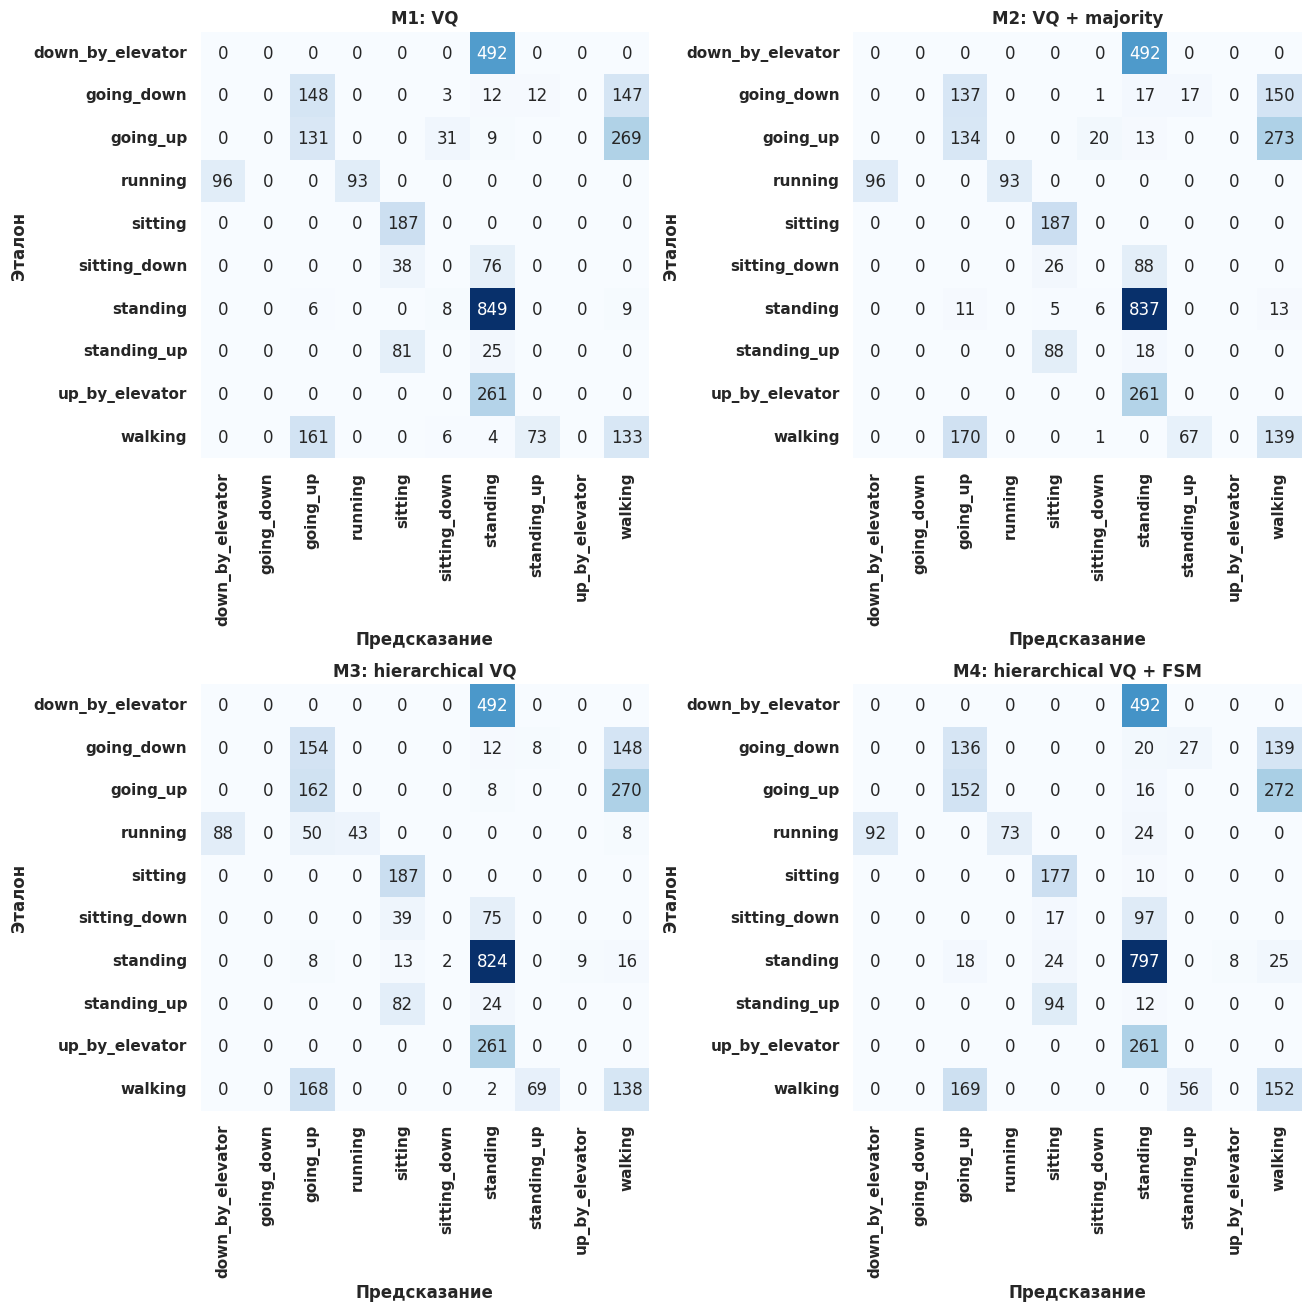

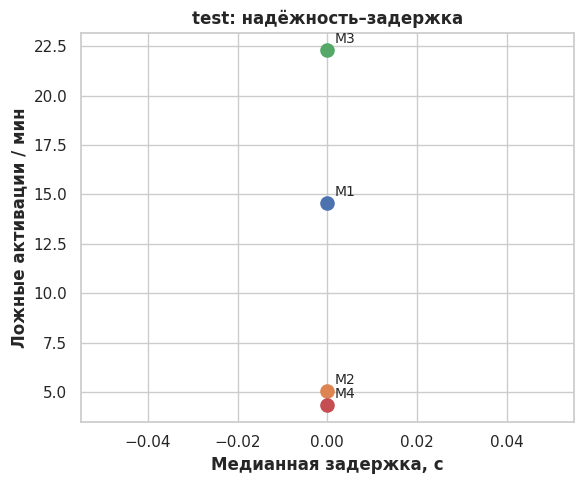

In [60]:
X_test, y_test, _ = splits["test"]
one_test, two_test, confidence_test = raw_predictions(X_test)
predictions = {
    "M1: VQ": one_test,
    "M2: VQ + majority": filtered(one_test, slices["test"], window=best_window),
    "M3: hierarchical VQ": two_test,
    "M4: hierarchical VQ + FSM": filtered(two_test, slices["test"],
        confidence=confidence_test, confirmations=best_n, threshold=best_q),
}

comparison = pd.DataFrame([
    dict(method=name, **cm.evaluate(y_test, pred, slices["test"], **METRIC_PARAMS),
         macro_f1=f1_score(y_test, pred, labels=CLASS_IDS, average="macro", zero_division=0))
    for name, pred in predictions.items()
]).set_index("method")

display(comparison.round(3))
print(f"Параметры M2: окно большинства {best_window}.")
print(f"Параметры M4: подтверждений {best_n}. Порог уверенности {best_q:.2f}.")

cm.build_plot_prediction_reference(
    predictions, y_test, labels=CLASS_IDS, label_names=LABEL_NAMES, fig_dir=None)
plt.show()
cm.build_plot_reliability_latency_compare(comparison.reset_index(), fig_dir=None)
plt.show()


In [61]:
# Проверяем каузальность обоих фильтров на синтетическом примере.
rng = np.random.default_rng(SEED)
probe = rng.choice(CLASS_IDS, size=80)
confidence = rng.random(len(probe))
for n in cm.CONFIRMATION_WINDOWS:
    assert cm.assert_causal(probe, confidence, n, best_q, **FSM_PARAMS)
for w in cm.MAJORITY_WINDOWS:
    full = cm.causal_majority(probe, w)
    for end in (1, 5, 23, 80):
        np.testing.assert_array_equal(cm.causal_majority(probe[:end], w), full[:end])
print("Каузальность фильтров подтверждена. Каждая запись обрабатывается с отдельным состоянием.")


Каузальность фильтров подтверждена. Каждая запись обрабатывается с отдельным состоянием.


## LSTM для HuGaDB

### LSTM many-to-many для всех записей десяти классов

Из полного HuGaDB исключаются только bicycling и sitting_in_car. Они представлены одним участником и не позволяют провести независимую оценку.

Все остальные записи, достаточно длинные для одного окна, целиком попадают в train, conf или test. Одна запись не делится между разделами. Разбиение детерминированное и стремится оставить около 20% окон каждого класса в conf и test.

Для каждого окна строятся те же 152 признака, что и выше:

1) среднее
2) стандартное отклонение
3) RMS
4) RMS разностей по 38 каналам

StandardScaler и PCA до 16 компонент обучаются только на train. Затем LSTM получает последовательность PCA-признаков одной записи и выдаёт метку для каждого окна. Голова модели состоит из двух полносвязных слоёв с ReLU и Dropout между ними.

In [62]:
import random
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

LSTM_SEED = 42
LSTM_CONF_FRACTION, LSTM_TEST_FRACTION = 0.20, 0.20
LSTM_WINDOW, LSTM_STRIDE = WINDOW, STRIDE
LSTM_DT = DT
LSTM_EXCLUDED = {"bicycling", "sitting_in_car"}
LSTM_CLASS_NAMES = sorted(EXPECTED_CLASSES - LSTM_EXCLUDED)
LSTM_CLASS_TO_ID = {name: i + 1 for i, name in enumerate(LSTM_CLASS_NAMES)}
LSTM_CLASS_IDS = tuple(LSTM_CLASS_TO_ID.values())
LSTM_ID_TO_NAME = {value: key for key, value in LSTM_CLASS_TO_ID.items()}
LSTM_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if LSTM_DEVICE.type == "cpu":
    print("CUDA недоступна. В среде не найден драйвер NVIDIA или устройство GPU. Используется CPU.")
else:
    print(f"Используется CUDA: {torch.cuda.get_device_name(0)}")

Используется CUDA: NVIDIA GeForce GTX 1660 Ti


In [63]:
# Сначала читаем только метки. По ним каждая целая запись назначается одному разделу.
lstm_records = []
for path in sorted(DATA.glob("*.csv")):
    labels = pd.read_csv(path, usecols=["activity"])["activity"]
    present = set(labels.unique())
    if present & LSTM_EXCLUDED:
        continue
    assert present <= set(LSTM_CLASS_NAMES), (path.name, present)
    counts = labels.value_counts().reindex(LSTM_CLASS_NAMES, fill_value=0).to_numpy(dtype=float)
    if len(labels) >= LSTM_WINDOW:
        lstm_records.append({"path": path, "record_id": path.stem, "counts": counts})

assert lstm_records, "Нет записей для LSTM"

In [64]:
# Формируем итоговое разбиение на train, conf и test для M1-M4.
def balanced_holdout(records, fraction, seed):
    totals = np.sum([record["counts"] for record in records], axis=0)
    target_counts, target_total = totals * fraction, totals.sum() * fraction
    available = list(np.random.default_rng(seed).permutation(len(records)))
    selected, selected_counts = [], np.zeros_like(totals)

    def cost(counts):
        class_error = np.mean(((counts - target_counts) / np.maximum(target_counts, 1.0)) ** 2)
        size_error = ((counts.sum() - target_total) / max(target_total, 1.0)) ** 2
        return class_error + 0.20 * size_error

    while available and selected_counts.sum() < target_total:
        best_pos = min(range(len(available)), key=lambda pos: cost(
            selected_counts + records[available[pos]]["counts"]))
        index = available.pop(best_pos)
        selected.append(records[index])
        selected_counts += records[index]["counts"]
    selected_ids = {record["record_id"] for record in selected}
    return selected, [record for record in records if record["record_id"] not in selected_ids]

lstm_test_records, remaining_records = balanced_holdout(lstm_records, LSTM_TEST_FRACTION, LSTM_SEED)
lstm_conf_records, lstm_train_records = balanced_holdout(
    remaining_records, LSTM_CONF_FRACTION / (1.0 - LSTM_TEST_FRACTION), LSTM_SEED + 1)
lstm_split = {"train": lstm_train_records, "conf": lstm_conf_records, "test": lstm_test_records}
all_paths = [record["path"] for records in lstm_split.values() for record in records]
assert len(all_paths) == len(set(all_paths)) == len(lstm_records)
assert all(len(records) for records in lstm_split.values())

lstm_balance = pd.DataFrame({
    f"{split}_frames": np.sum([r["counts"] for r in records], axis=0)
    for split, records in lstm_split.items()
}, index=LSTM_CLASS_NAMES)
for split in ("conf", "test"):
    lstm_balance[f"{split}_share"] = lstm_balance[f"{split}_frames"] / lstm_balance[["train_frames", "conf_frames", "test_frames"]].sum(axis=1)
assert (lstm_balance[["train_frames", "conf_frames", "test_frames"]] > 0).all().all()
display(lstm_balance.round(3))
print(f"Число записей. Train: {len(lstm_split['train'])}. Conf: {len(lstm_split['conf'])}. Test: {len(lstm_split['test'])}.")
print(f"Устройство для обучения: {LSTM_DEVICE}.")


,train_frames,conf_frames,test_frames,conf_share,test_share
down_by_elevator,41672.0,14082.0,13975.0,0.202,0.200
going_down,69512.0,23813.0,23312.0,0.204,0.200
going_up,78705.0,26718.0,26181.0,0.203,0.199
running,43081.0,14099.0,14473.0,0.197,0.202
sitting,144886.0,48373.0,48590.0,0.200,0.201
sitting_down,14319.0,4934.0,4859.0,0.205,0.202
standing,196713.0,65751.0,66191.0,0.200,0.201
standing_up,13511.0,4382.0,4480.0,0.196,0.200
up_by_elevator,52894.0,18060.0,18190.0,0.203,0.204
walking,408099.0,135930.0,134991.0,0.200,0.199


Число записей. Train: 452. Conf: 85. Test: 63.
Устройство для обучения: cuda.


In [65]:
def lstm_window_features(path):
    """Те же mean/std/RMS/RMS(diff) признаки, что в make_split выше, но векторизованно."""
    df = pd.read_csv(path)
    columns = [c for c in df if c.startswith(("accelerometer_", "gyroscope_", "EMG_"))]
    assert len(columns) == 38, (path.name, columns)
    signal = df[columns].to_numpy(dtype=np.float32)
    labels = df.activity.map(LSTM_CLASS_TO_ID).to_numpy(dtype=np.int64)
    assert np.isfinite(signal).all() and np.isfinite(labels).all(), path.name

    starts = np.arange(0, len(signal) - LSTM_WINDOW + 1, LSTM_STRIDE)
    stops = starts + LSTM_WINDOW
    cumulative = np.vstack([np.zeros((1, signal.shape[1]), dtype=np.float64),
                            np.cumsum(signal, axis=0, dtype=np.float64)])
    cumulative_sq = np.vstack([np.zeros((1, signal.shape[1]), dtype=np.float64),
                               np.cumsum(signal ** 2, axis=0, dtype=np.float64)])
    mean = (cumulative[stops] - cumulative[starts]) / LSTM_WINDOW
    mean_sq = (cumulative_sq[stops] - cumulative_sq[starts]) / LSTM_WINDOW
    std = np.sqrt(np.maximum(mean_sq - mean ** 2, 0.0))
    rms = np.sqrt(mean_sq)

    diffs = np.diff(signal, axis=0)
    cumulative_diff_sq = np.vstack([np.zeros((1, signal.shape[1]), dtype=np.float64),
                                    np.cumsum(diffs ** 2, axis=0, dtype=np.float64)])
    diff_rms = np.sqrt((cumulative_diff_sq[stops - 1] - cumulative_diff_sq[starts]) / (LSTM_WINDOW - 1))
    features = np.concatenate([mean, std, rms, diff_rms], axis=1).astype(np.float32)

    # Метка привязана к концу окна, как и в блоке K-means.
    return features, labels[stops - 1]

In [66]:
# Извлекаем признаки из всех записей, пригодных для окна. В памяти остаются только последовательности окон.
lstm_raw = {}
for split_records in lstm_split.values():
    for record in split_records:
        lstm_raw[record["record_id"]] = lstm_window_features(record["path"])

train_flat = np.concatenate([lstm_raw[r["record_id"]][0] for r in lstm_split["train"]], axis=0)
lstm_scaler = StandardScaler().fit(train_flat)
lstm_pca = PCA(n_components=16, svd_solver="full", random_state=LSTM_SEED).fit(
    lstm_scaler.transform(train_flat))

lstm_sequences = {split: [] for split in lstm_split}
for split, records in lstm_split.items():
    for record in records:
        features, target = lstm_raw[record["record_id"]]
        pcs = lstm_pca.transform(lstm_scaler.transform(features)).astype(np.float32)
        lstm_sequences[split].append((record["record_id"], pcs, target))
del lstm_raw, train_flat

print(f"Доля объяснённой дисперсии PCA: {lstm_pca.explained_variance_ratio_.sum():.3f}.")
print(f"Окон train: {sum(len(x) for _, x, _ in lstm_sequences['train'])}.")
print(f"Окон conf: {sum(len(x) for _, x, _ in lstm_sequences['conf'])}.")
print(f"Окон test: {sum(len(x) for _, x, _ in lstm_sequences['test'])}.")


Доля объяснённой дисперсии PCA: 0.885.
Окон train: 173276.
Окон conf: 58609.
Окон test: 58655.


In [67]:
class ManyToManyLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, n_classes, n_layers):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=n_layers, batch_first=True,
                            dropout=0.20 if n_layers > 1 else 0.0)
        self.head = nn.Sequential(
            nn.Linear(hidden_size, 64), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(64, n_classes),
        )

    def forward(self, x, lengths):
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=x.shape[1])
        return self.head(out)

In [68]:
def lstm_batches(sequences, batch_size, shuffle, epoch=0):
    # Записи близкой длины объединяются в один batch. Это уменьшает padding и сохраняет порядок внутри записи.
    indices = np.argsort([len(features) for _, features, _ in sequences])
    groups = [indices[start:start + batch_size] for start in range(0, len(indices), batch_size)]
    if shuffle:
        np.random.default_rng(LSTM_SEED + epoch).shuffle(groups)
    for group in groups:
        batch = [sequences[i] for i in group]
        lengths = torch.tensor([len(features) for _, features, _ in batch], dtype=torch.long)
        max_length = int(lengths.max())
        x = torch.zeros((len(batch), max_length, 16), dtype=torch.float32)
        y = torch.full((len(batch), max_length), -100, dtype=torch.long)
        for row, (_, features, target) in enumerate(batch):
            x[row, :len(features)] = torch.from_numpy(features)
            y[row, :len(target)] = torch.from_numpy(target - 1)
        yield x.to(LSTM_DEVICE), y.to(LSTM_DEVICE), lengths

In [69]:
torch.manual_seed(LSTM_SEED)
random.seed(LSTM_SEED)
np.random.seed(LSTM_SEED)
LSTM_EPOCHS, LSTM_BATCH_SIZE = 8, 8
train_targets = np.concatenate([target for _, _, target in lstm_sequences["train"]])
train_counts = np.bincount(train_targets - 1, minlength=len(LSTM_CLASS_IDS))
class_weights = train_counts.sum() / (len(LSTM_CLASS_IDS) * np.maximum(train_counts, 1))
loss_weights = torch.tensor(class_weights, dtype=torch.float32, device=LSTM_DEVICE)

def train_lstm(n_layers, title):
    torch.manual_seed(LSTM_SEED + n_layers)
    model = ManyToManyLSTM(16, 96, len(LSTM_CLASS_IDS), n_layers=n_layers).to(LSTM_DEVICE)
    criterion = nn.CrossEntropyLoss(weight=loss_weights, ignore_index=-100)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    history = []
    for epoch in range(LSTM_EPOCHS):
        model.train()
        loss_sum, n_windows = 0.0, 0
        for x_batch, y_batch, lengths in lstm_batches(
                lstm_sequences["train"], LSTM_BATCH_SIZE, shuffle=True, epoch=epoch):
            optimizer.zero_grad()
            logits = model(x_batch, lengths)
            loss = criterion(logits.reshape(-1, len(LSTM_CLASS_IDS)), y_batch.reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            valid = int((y_batch != -100).sum())
            loss_sum += float(loss.detach()) * valid
            n_windows += valid
        history.append(loss_sum / n_windows)
        print(f"{title}. Эпоха {epoch + 1:02d} из {LSTM_EPOCHS}. Средняя loss: {history[-1]:.4f}.")
    return model, history

In [70]:
# M1 и M2 используют однослойный LSTM. M3 и M4 используют двухслойный LSTM.
lstm_one_model, lstm_one_history = train_lstm(n_layers=1, title="one-level")
lstm_two_model, lstm_two_history = train_lstm(n_layers=2, title="two-level")

one-level. Эпоха 01 из 8. Средняя loss: 1.9270.
one-level. Эпоха 02 из 8. Средняя loss: 1.2121.
one-level. Эпоха 03 из 8. Средняя loss: 0.8217.
one-level. Эпоха 04 из 8. Средняя loss: 0.6947.
one-level. Эпоха 05 из 8. Средняя loss: 0.6373.
one-level. Эпоха 06 из 8. Средняя loss: 0.6446.
one-level. Эпоха 07 из 8. Средняя loss: 0.5768.
one-level. Эпоха 08 из 8. Средняя loss: 0.6206.
two-level. Эпоха 01 из 8. Средняя loss: 1.9284.
two-level. Эпоха 02 из 8. Средняя loss: 1.2268.
two-level. Эпоха 03 из 8. Средняя loss: 0.9868.
two-level. Эпоха 04 из 8. Средняя loss: 0.8388.
two-level. Эпоха 05 из 8. Средняя loss: 0.7150.
two-level. Эпоха 06 из 8. Средняя loss: 0.6625.
two-level. Эпоха 07 из 8. Средняя loss: 0.6153.
two-level. Эпоха 08 из 8. Средняя loss: 0.5874.


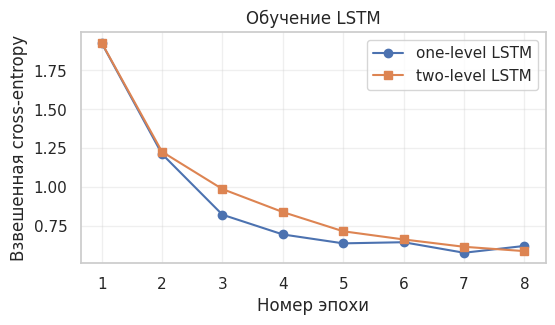

In [71]:
plt.figure(figsize=(6, 3))
plt.plot(range(1, LSTM_EPOCHS + 1), lstm_one_history, marker="o", label="one-level LSTM")
plt.plot(range(1, LSTM_EPOCHS + 1), lstm_two_history, marker="s", label="two-level LSTM")
plt.xlabel("Номер эпохи")
plt.ylabel("Взвешенная cross-entropy")
plt.title("Обучение LSTM")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [72]:
@torch.no_grad()
def lstm_predict(model, sequences):
    """Предсказания и confidence-margin без смешивания границ разных записей."""
    model.eval()
    y_true, y_pred, confidence, metadata = [], [], [], []
    for record_id, features, target in sequences:
        x = torch.from_numpy(features).unsqueeze(0).to(LSTM_DEVICE)
        lengths = torch.tensor([len(features)], dtype=torch.long)
        logits = model(x, lengths).squeeze(0)
        probabilities = torch.softmax(logits, dim=-1)
        top2 = torch.topk(probabilities, k=2, dim=-1).values
        y_true.append(target)
        y_pred.append(logits.argmax(dim=-1).cpu().numpy() + 1)
        confidence.append((top2[:, 0] - top2[:, 1]).cpu().numpy())
        metadata.extend((record_id, start, start + LSTM_WINDOW - 1)
                        for start in range(0, len(features) * LSTM_STRIDE, LSTM_STRIDE))
    y_true, y_pred, confidence = np.concatenate(y_true), np.concatenate(y_pred), np.concatenate(confidence)
    meta = pd.DataFrame(metadata, columns=["record_id", "window_start_frame", "window_end_frame"])
    slices, _ = cm.record_slices(tuple(meta.record_id.drop_duplicates()), meta)
    return y_true, y_pred, confidence, slices

def lstm_majority(raw, slices, window):
    return cm.apply_per_record(raw, slices, lambda x: cm.causal_majority(x, window))[0]

def lstm_fsm(raw, confidence, slices, confirmations, threshold):
    return cm.apply_per_record(
        raw, slices,
        lambda x, c: cm.transition_automaton(
            x, c, confirmations, threshold,
            neutral_id=LSTM_CLASS_TO_ID["standing"], label_names=LSTM_ID_TO_NAME, distractor_id=None),
        confidence)[0]

In [73]:
LSTM_METRIC_PARAMS = dict(active_command_ids=LSTM_CLASS_IDS, window_step_seconds=LSTM_DT,
                          iou_threshold=cm.EVENT_IOU_THRESHOLD)
lstm_y_conf, lstm_one_conf, _, lstm_conf_slices = lstm_predict(lstm_one_model, lstm_sequences["conf"])
_, lstm_two_conf, lstm_two_confidence, check_conf_slices = lstm_predict(lstm_two_model, lstm_sequences["conf"])
assert lstm_conf_slices == check_conf_slices

lstm_tuning_rows = []
for window in cm.MAJORITY_WINDOWS:
    prediction = lstm_majority(lstm_one_conf, lstm_conf_slices, window)
    lstm_tuning_rows.append(dict(method="M2", majority_window=window,
                                 **cm.evaluate(lstm_y_conf, prediction, lstm_conf_slices, **LSTM_METRIC_PARAMS)))
for confirmations, threshold in product(cm.CONFIRMATION_WINDOWS, cm.CONFIDENCE_THRESHOLDS):
    prediction = lstm_fsm(lstm_two_conf, lstm_two_confidence, lstm_conf_slices, confirmations, threshold)
    lstm_tuning_rows.append(dict(method="M4", confirmations=confirmations, threshold=threshold,
                                 **cm.evaluate(lstm_y_conf, prediction, lstm_conf_slices, **LSTM_METRIC_PARAMS)))
lstm_tuning = pd.DataFrame(lstm_tuning_rows)

def choose_lstm_params(method):
    if method == "M4":
        baseline_f1 = max(
            cm.evaluate(lstm_y_conf, lstm_one_conf, lstm_conf_slices, **LSTM_METRIC_PARAMS)["event_f1@50"],
            choose_lstm_params("M2")["event_f1@50"],
            cm.evaluate(lstm_y_conf, lstm_two_conf, lstm_conf_slices, **LSTM_METRIC_PARAMS)["event_f1@50"],
        )
        return cm.choose_m4_params(lstm_tuning[lstm_tuning.method == method], baseline_f1=baseline_f1)
    return lstm_tuning[lstm_tuning.method == method].sort_values(
        ["event_f1@50", "false_activations_per_min", "p95_delay_s"],
        ascending=[False, True, True], kind="stable", na_position="last").iloc[0]

lstm_best2, lstm_best4 = choose_lstm_params("M2"), choose_lstm_params("M4")
lstm_best_window = int(lstm_best2.majority_window)
lstm_best_n, lstm_best_q = int(lstm_best4.confirmations), float(lstm_best4.threshold)
display(lstm_best4[["conf_baseline_f1@50", "conf_best_m4_f1@50", "conf_min_m4_f1@50", "event_f1@50"]])


In [74]:
display(pd.DataFrame([
    {"method": "M2", "majority_window": lstm_best_window, "confirmations": "-",
     "confidence_threshold": "-", "conf_event_f1@50": lstm_best2["event_f1@50"],
     "conf_false_activations_per_min": lstm_best2.false_activations_per_min},
    {"method": "M4", "majority_window": "-", "confirmations": lstm_best_n,
     "confidence_threshold": lstm_best_q, "conf_event_f1@50": lstm_best4["event_f1@50"],
     "conf_false_activations_per_min": lstm_best4.false_activations_per_min},
]).round(3))

,method,majority_window,confirmations,confidence_threshold,conf_event_f1@50,conf_false_activations_per_min
0,M2,5,-,-,0.586,3.923
1,M4,-,1,0.7,0.678,2.211


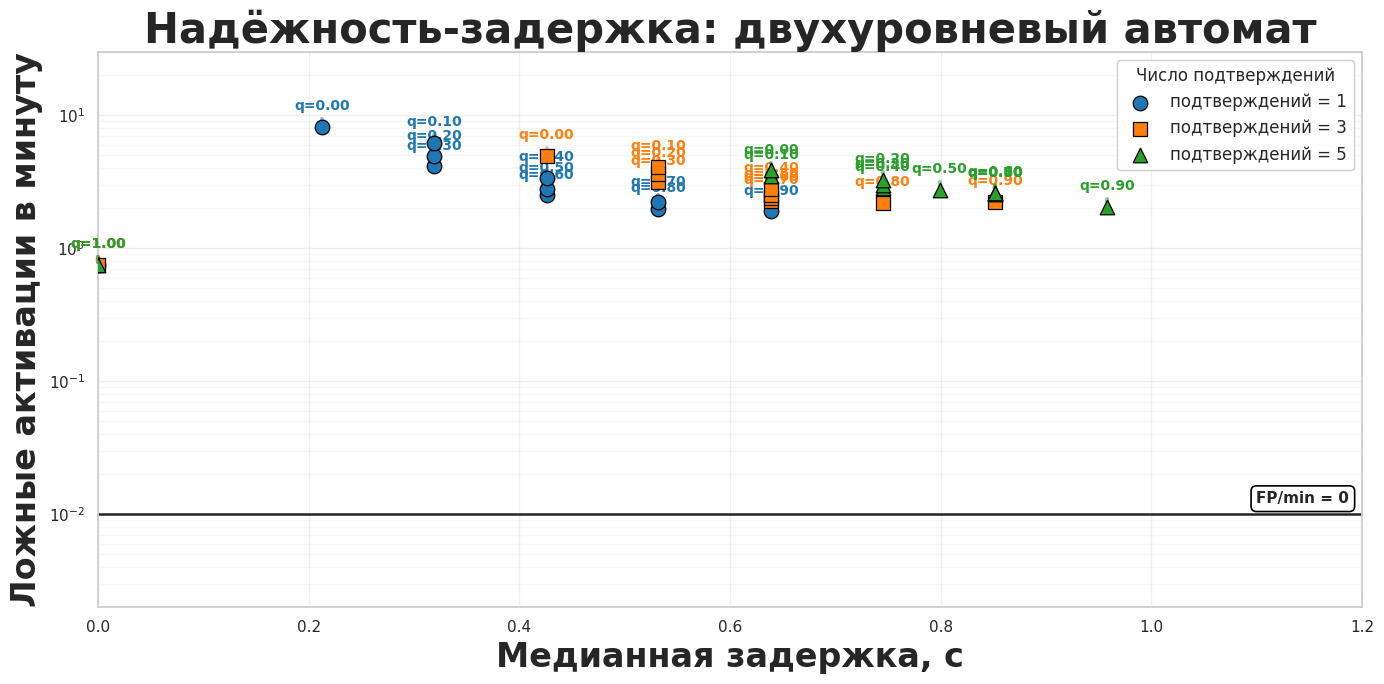

In [75]:
# Строим для M4 такую же диаграмму надёжности и задержки, как в блоке VQ.
cm.build_plot_reliability_latency_m4(
    lstm_tuning.assign(method=lambda df: df.method.replace({"M4": "M4_two_level_automaton"})), fig_dir=None)
plt.show()

In [76]:
lstm_y_test, lstm_one_test, _, lstm_test_slices = lstm_predict(lstm_one_model, lstm_sequences["test"])
_, lstm_two_test, lstm_two_confidence, check_test_slices = lstm_predict(lstm_two_model, lstm_sequences["test"])

lstm_predictions = {
    "M1: one-level LSTM": lstm_one_test,
    "M2: one-level LSTM + majority": lstm_majority(lstm_one_test, lstm_test_slices, lstm_best_window),
    "M3: two-level LSTM": lstm_two_test,
    "M4: two-level LSTM + FSM": lstm_fsm(
        lstm_two_test, lstm_two_confidence, lstm_test_slices, lstm_best_n, lstm_best_q),
}

lstm_comparison = pd.DataFrame([
    dict(method=name, **cm.evaluate(lstm_y_test, prediction, lstm_test_slices, **LSTM_METRIC_PARAMS),
         macro_f1=f1_score(lstm_y_test, prediction, labels=LSTM_CLASS_IDS, average="macro", zero_division=0))
    for name, prediction in lstm_predictions.items()
]).set_index("method")
display(lstm_comparison.round(3))
print(f"Параметры M2: окно большинства {lstm_best_window}.")
print(f"Параметры M4: подтверждений {lstm_best_n}. Порог уверенности {lstm_best_q:.2f}.")

,frame_accuracy,event_f1@10,event_f1@25,event_f1@50,event_precision,event_recall,false_activations_per_min,median_delay_s,p95_delay_s,double_commands_per_transition,missed_commands,reference_events,predicted_events,macro_f1
method,,,,,,,,,,,,,,
M1: one-level LSTM,0.785,0.604,0.563,0.464,0.354,0.674,8.983,0.319,1.278,0.368,248,760,1447,0.599
M2: one-level LSTM + majority,0.774,0.712,0.663,0.513,0.432,0.632,6.072,0.532,1.491,0.188,280,760,1112,0.580
M3: two-level LSTM,0.786,0.612,0.579,0.468,0.362,0.662,8.502,0.319,1.171,0.317,257,760,1388,0.591
M4: two-level LSTM + FSM,0.767,0.799,0.772,0.633,0.646,0.620,2.479,0.532,1.384,0.020,289,760,729,0.577


Параметры M2: окно большинства 5.
Параметры M4: подтверждений 1. Порог уверенности 0.70.


## Вывод по LSTM

Сравнение в таблице выше показывает качество четырёх LSTM-вариантов. Для выбора лучшего метода нужно сопоставить:

1) F1 при IoU 0.10, 0.25 и 0.50
2) число ложных активаций в минуту
3) число двойных команд на один переход
4) задержку обнаружения команды

M4 использует двухуровневую LSTM, порог уверенности и конечный автомат. Эти механизмы предназначены для уменьшения ложных и двойных срабатываний.

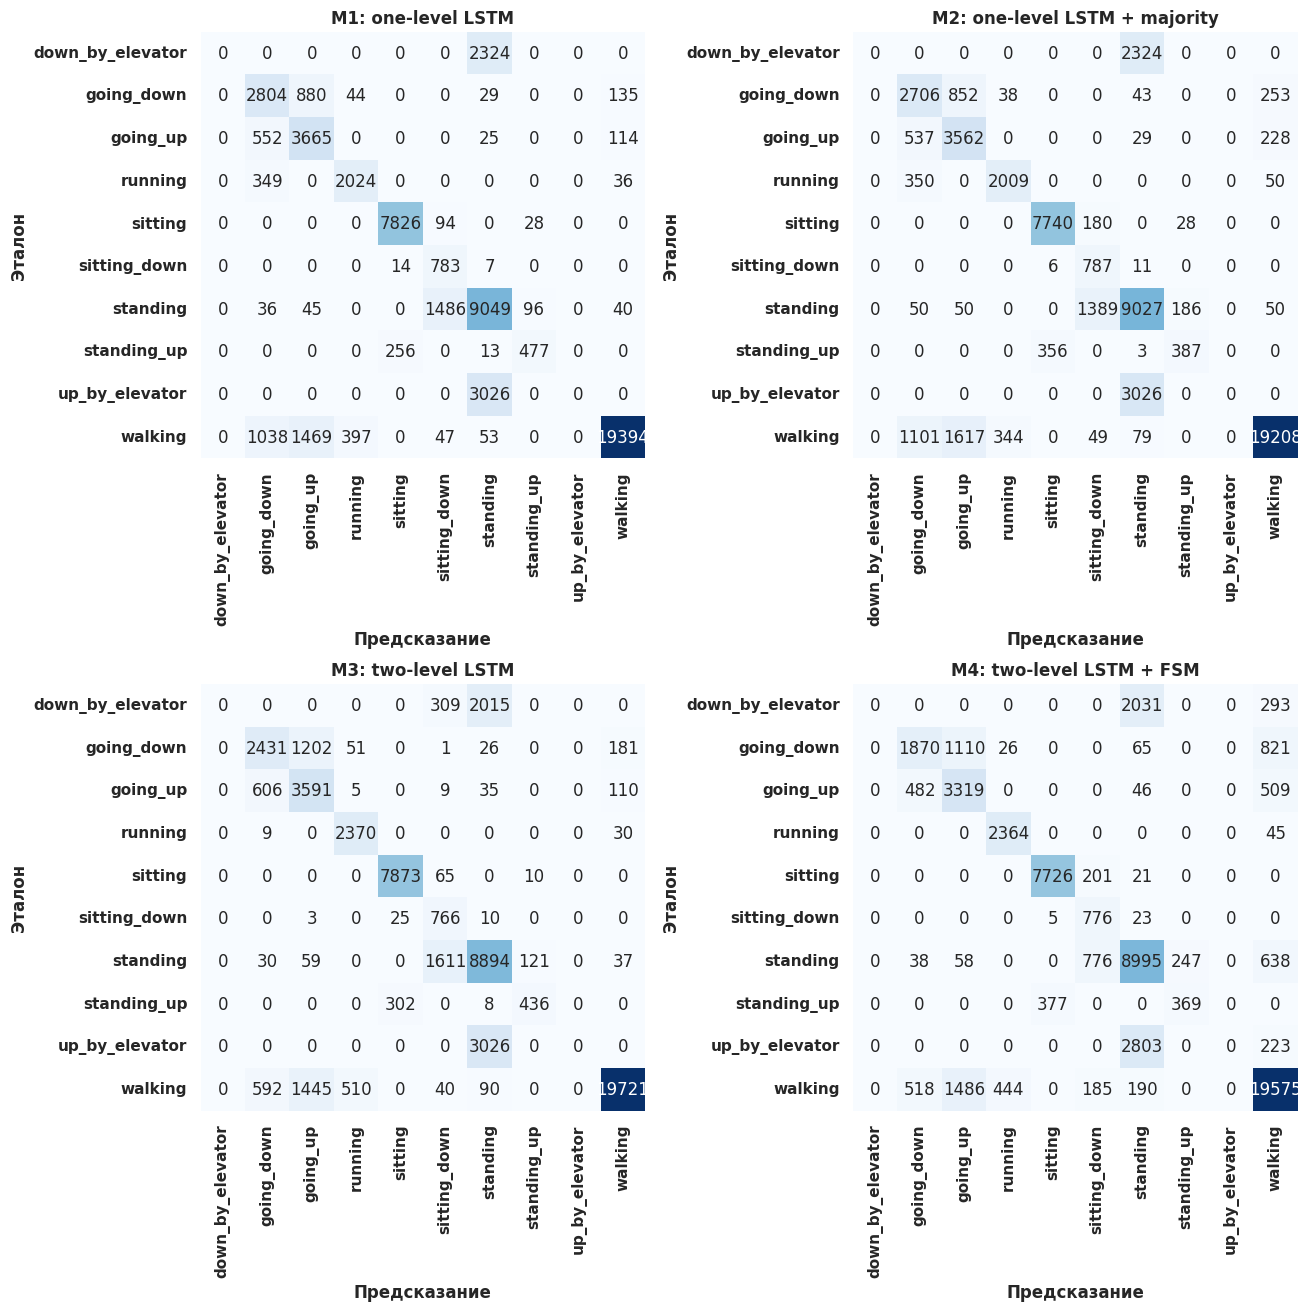

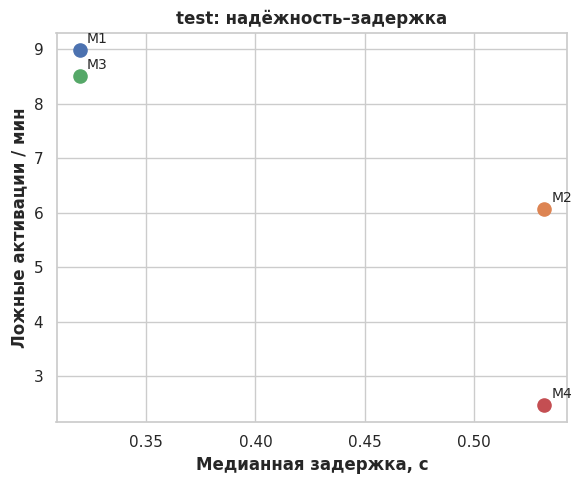

In [77]:
cm.build_plot_prediction_reference(
    lstm_predictions, lstm_y_test, labels=LSTM_CLASS_IDS, label_names=LSTM_ID_TO_NAME, fig_dir=None)
plt.show()
cm.build_plot_reliability_latency_compare(lstm_comparison.reset_index(), fig_dir=None)
plt.show()

In [78]:
# Проверяем каузальность тех же двух фильтров для выхода LSTM.
probe = np.random.default_rng(LSTM_SEED).choice(LSTM_CLASS_IDS, size=80)
probe_confidence = np.random.default_rng(LSTM_SEED + 1).random(len(probe))
assert cm.assert_causal(probe, probe_confidence, lstm_best_n, lstm_best_q,
                         neutral_id=LSTM_CLASS_TO_ID["standing"], label_names=LSTM_ID_TO_NAME, distractor_id=None)
for end in (1, 5, 23, 80):
    np.testing.assert_array_equal(cm.causal_majority(probe[:end], lstm_best_window),
                                  cm.causal_majority(probe, lstm_best_window)[:end])
print("Каузальность фильтров LSTM подтверждена.")


Каузальность фильтров LSTM подтверждена.
